# Two-Plot Rescaling Check

Notebook minimale: cambia solo la funzione `rescale_x(df)`, poi rilancia la cella dei due plot.

In [1]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = Path('.') if Path('recovered_orex_metrics.csv').exists() else Path('plot/orex_recovered_from_txt')
FIG_DIR = OUT_DIR / 'two_plot_rescaling_figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

files = [
    OUT_DIR / 'recovered_orex_metrics.csv',
    OUT_DIR / 'recovered_neorex_eval_metrics.csv',
    OUT_DIR / 'recovered_orex_d3_metrics.csv',
]

def infer_defect_size(row):
    if 'defect_size' in row and pd.notna(row['defect_size']):
        return int(row['defect_size'])
    text = ' '.join(str(row.get(k, '')) for k in ['study_name', 'run_name', 'output_dir', 'wandb_run_name'])
    m = re.search(r'[_-]d(\d+)', text)
    return int(m.group(1)) if m else 2

frames = []
for path in files:
    frame = pd.read_csv(path)
    frame['source_file'] = path.name
    frames.append(frame)

data = pd.concat(frames, ignore_index=True, sort=False)
data['algorithm'] = data['algorithm'].astype(str).str.lower().map({'orex': 'OREX', 'neorex': 'NEO-REX pretrained'}).fillna(data['algorithm'])
data['nreplicas'] = pd.to_numeric(data['nreplicas'], errors='coerce').astype(int)
data['nsteps'] = pd.to_numeric(data['nsteps'], errors='coerce').astype(int)
data['nsteps_raw'] = data['nsteps'].astype(float)
data['nsteps_plus1'] = data['nsteps_raw'] + 1.0
data['swap_acceptance'] = pd.to_numeric(data['swap_acceptance'], errors='coerce')
data['work_mean'] = pd.to_numeric(data['work_mean'], errors='coerce')
data['work_sem'] = pd.to_numeric(data['work_sem'], errors='coerce')
data['total_proposed'] = pd.to_numeric(data['total_proposed'], errors='coerce')
data['swap_acceptance_sem'] = np.sqrt(data['swap_acceptance'] * (1.0 - data['swap_acceptance']) / data['total_proposed'])
data['defect_size'] = data.apply(infer_defect_size, axis=1).astype(int)
data['defect_volume'] = data['defect_size'] ** 3
data['n_defect_plaquettes'] = 3.0 * data['defect_size'] ** 2 * (data['defect_size'] + 1.0)
data['nreplicas_f'] = data['nreplicas'].astype(float)
data['nr_minus_1'] = data['nreplicas_f'] - 1.0
data = data.sort_values(['algorithm', 'defect_size', 'nreplicas', 'nsteps']).reset_index(drop=True)

data[['algorithm', 'defect_size', 'defect_volume', 'n_defect_plaquettes', 'nreplicas', 'nsteps', 'nsteps_raw', 'nsteps_plus1', 'swap_acceptance', 'work_mean']]


,algorithm,defect_size,defect_volume,n_defect_plaquettes,nreplicas,nsteps,nsteps_raw,nsteps_plus1,swap_acceptance,work_mean
0,NEO-REX pretrained,2,8,36.0,4,2,2.0,3.0,0.078464,6.952978
1,NEO-REX pretrained,2,8,36.0,4,4,4.0,5.0,0.199271,3.530432
2,NEO-REX pretrained,2,8,36.0,4,6,6.0,7.0,0.289141,2.367685
3,NEO-REX pretrained,2,8,36.0,4,8,8.0,9.0,0.353490,1.789984
4,NEO-REX pretrained,2,8,36.0,8,2,2.0,3.0,0.457455,1.172992
5,NEO-REX pretrained,2,8,36.0,8,4,4.0,5.0,0.583281,0.619129
6,NEO-REX pretrained,2,8,36.0,8,6,6.0,7.0,0.648393,0.428084
7,NEO-REX pretrained,2,8,36.0,8,8,8.0,9.0,0.690379,0.322369
8,OREX,2,8,36.0,4,0,0.0,1.0,0.010286,15.468660
9,OREX,2,8,36.0,4,2,2.0,3.0,0.058750,7.980036


## CAMBIA QUI

In [ ]:

def rescale_x(df):
    # Scrivi qui il rescaling da testare.
    # Esempi utili:
    # return df['nsteps_raw'] * df['nr_minus_1']**2 / df['defect_volume']
    # return df['nsteps_plus1'] * df['nr_minus_1']**2 / df['defect_volume']
    # return df['nsteps_plus1'] * df['nreplicas_f']**2 / df['defect_volume']
    # return np.sqrt(df['nsteps_plus1']) * df['nr_minus_1'] / np.sqrt(df['defect_volume'])
    # return np.sqrt(df['nsteps_plus1']) * df['nr_minus_1'] / np.sqrt(df['n_defect_plaquettes'])
    return (df['nsteps_raw']+1) * (df['nr_minus_1'])**2 / df['defect_volume'] #+0.1*( (df['nsteps_raw']+1) * (df['nr_minus_1'])**2 / df['defect_volume'])**2

x_label = r'$(n_{\mathrm{steps}}+1)(N_r-1)^2/V_{\mathrm{def}}$'


## Due Plot

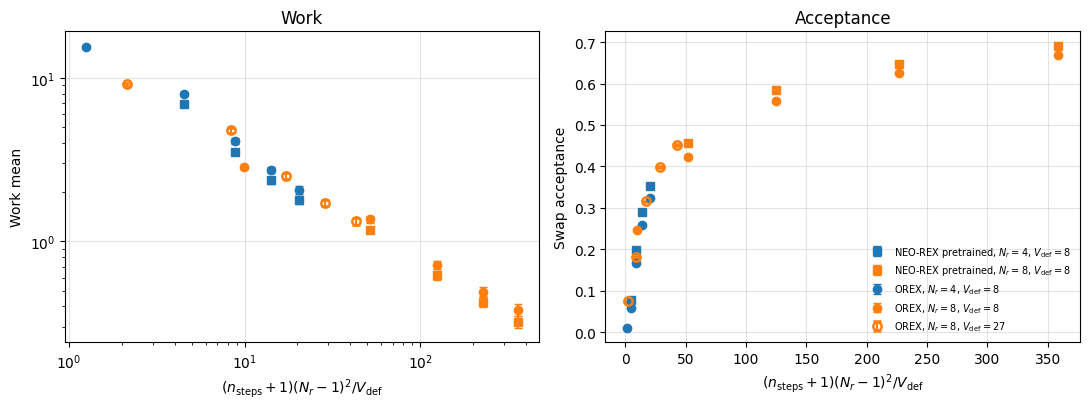

,algorithm,defect_size,defect_volume,n_defect_plaquettes,nreplicas,nsteps,x,work_mean,swap_acceptance
0,NEO-REX pretrained,2,8,36.0,4,2,4.514062,6.952978,0.078464
1,NEO-REX pretrained,2,8,36.0,4,4,8.789062,3.530432,0.199271
2,NEO-REX pretrained,2,8,36.0,4,6,14.076563,2.367685,0.289141
3,NEO-REX pretrained,2,8,36.0,4,8,20.376562,1.789984,0.353490
4,NEO-REX pretrained,2,8,36.0,8,2,52.139063,1.172992,0.457455
5,NEO-REX pretrained,2,8,36.0,8,4,124.414062,0.619129,0.583281
6,NEO-REX pretrained,2,8,36.0,8,6,226.701563,0.428084,0.648393
7,NEO-REX pretrained,2,8,36.0,8,8,359.001563,0.322369,0.690379
8,OREX,2,8,36.0,4,0,1.251562,15.468660,0.010286
9,OREX,2,8,36.0,4,2,4.514062,7.980036,0.058750


In [13]:

plot_data = data.copy()
plot_data['x'] = rescale_x(plot_data)

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))
markers = {'OREX': 'o', 'NEO-REX pretrained': 's'}
colors = {4: 'tab:blue', 8: 'tab:orange'}

for (algorithm, nreplicas, defect_volume), sub in plot_data.groupby(['algorithm', 'nreplicas', 'defect_volume'], sort=True):
    color = colors.get(int(nreplicas), '0.3')
    marker = markers.get(algorithm, 'o')
    filled = int(defect_volume) == 8
    face = color if filled else 'none'
    edge_width = 1.0 if filled else 1.8
    label = fr'{algorithm}, $N_r={int(nreplicas)}$, $V_{{\mathrm{{def}}}}={int(defect_volume)}$'

    axes[0].errorbar(
        sub['x'], sub['work_mean'], yerr=10*sub['work_sem'],
        marker=marker, linestyle='None', color=color,
        markerfacecolor=face, markeredgewidth=edge_width,
        capsize=3, label=label,
    )
    axes[1].errorbar(
        sub['x'], sub['swap_acceptance'], yerr=sub['swap_acceptance_sem'],
        marker=marker, linestyle='None', color=color,
        markerfacecolor=face, markeredgewidth=edge_width,
        capsize=3, label=label,
    )

axes[0].set_title('Work')
axes[0].set_xlabel(x_label)
axes[0].set_ylabel('Work mean')
axes[0].set_yscale('log')

axes[1].set_title('Acceptance')
axes[1].set_xlabel(x_label)
axes[1].set_ylabel('Swap acceptance')

# Usa log-x solo se il rescaling scelto e' strettamente positivo.
if (plot_data['x'] > 0).all():
    axes[0].set_xscale('log')
    #axes[1].set_xscale('log')

for ax in axes:
    ax.grid(True, alpha=0.35)

axes[1].legend(frameon=False, fontsize=7, loc='best')
fig.tight_layout()
fig.savefig(FIG_DIR / 'two_plot_custom_rescaling.png', dpi=180, bbox_inches='tight')
fig.savefig(FIG_DIR / 'two_plot_custom_rescaling.pdf', bbox_inches='tight')
plt.show()

plot_data[['algorithm', 'defect_size', 'defect_volume', 'n_defect_plaquettes', 'nreplicas', 'nsteps', 'x', 'work_mean', 'swap_acceptance']]


## Split REX from OREX / NEO-REX

Qui `nsteps=0` viene trattato come ramo `REX` con una sua funzione di scaling. I punti con `nsteps>0` restano `OREX` / `NEO-REX pretrained` e usano una seconda funzione.

In [4]:

def rescale_x_rex(df):
    # Scaling per i punti nsteps=0.
    # Esempi:
    # return df['nr_minus_1']**2 / df['defect_volume']
    # return df['nreplicas_f']**2 / df['defect_volume']
    # return df['nr_minus_1'] / np.sqrt(df['defect_volume'])
    return df['nr_minus_1']**2 / df['defect_volume']


def rescale_x_protocol(df):
    # Scaling per OREX / NEO-REX con nsteps>0.
    # Esempi:
    # return df['nsteps_raw'] * df['nr_minus_1']**2 / df['defect_volume']
    # return df['nsteps_raw'] * df['nreplicas_f']**2 / df['defect_volume']
    # return np.sqrt(df['nsteps_raw']) * df['nr_minus_1'] / np.sqrt(df['defect_volume'])
    return df['nsteps_raw'] * df['nr_minus_1']**2 / df['defect_volume']

x_label_split = (
    r'REX: $(N_r-1)^2/V_{\mathrm{def}}$; '
    r'OREX/NEO: $n_{\mathrm{steps}}(N_r-1)^2/V_{\mathrm{def}}$'
)


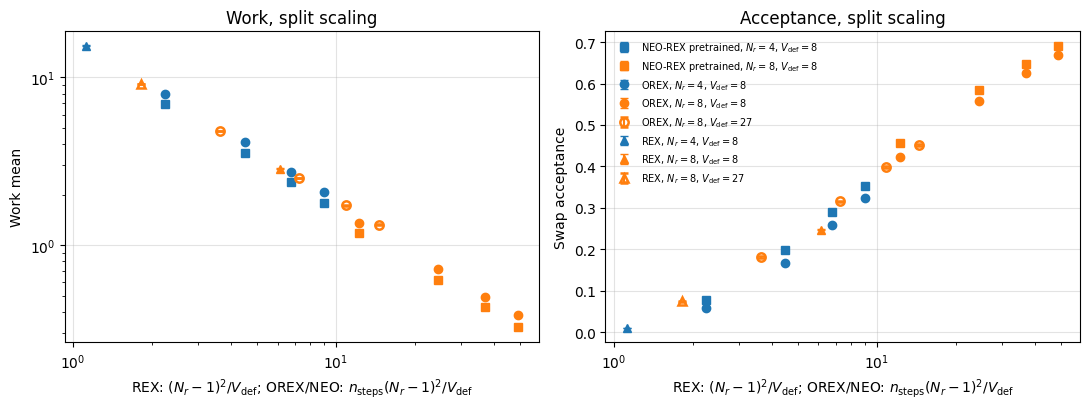

,protocol_family,algorithm,defect_size,defect_volume,nreplicas,nsteps,x_split,work_mean,swap_acceptance
0,NEO-REX pretrained,NEO-REX pretrained,2,8,4,2,2.250000,6.952978,0.078464
1,NEO-REX pretrained,NEO-REX pretrained,2,8,4,4,4.500000,3.530432,0.199271
2,NEO-REX pretrained,NEO-REX pretrained,2,8,4,6,6.750000,2.367685,0.289141
3,NEO-REX pretrained,NEO-REX pretrained,2,8,4,8,9.000000,1.789984,0.353490
4,NEO-REX pretrained,NEO-REX pretrained,2,8,8,2,12.250000,1.172992,0.457455
5,NEO-REX pretrained,NEO-REX pretrained,2,8,8,4,24.500000,0.619129,0.583281
6,NEO-REX pretrained,NEO-REX pretrained,2,8,8,6,36.750000,0.428084,0.648393
7,NEO-REX pretrained,NEO-REX pretrained,2,8,8,8,49.000000,0.322369,0.690379
8,REX,OREX,2,8,4,0,1.125000,15.468660,0.010286
9,OREX,OREX,2,8,4,2,2.250000,7.980036,0.058750


In [5]:

split_data = data.copy()
split_data['protocol_family'] = split_data['algorithm']
split_data.loc[split_data['nsteps'].eq(0), 'protocol_family'] = 'REX'

is_rex = split_data['protocol_family'].eq('REX')
split_data['x_split'] = np.nan
split_data.loc[is_rex, 'x_split'] = rescale_x_rex(split_data.loc[is_rex])
split_data.loc[~is_rex, 'x_split'] = rescale_x_protocol(split_data.loc[~is_rex])

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))
markers = {'REX': '^', 'OREX': 'o', 'NEO-REX pretrained': 's'}
colors = {4: 'tab:blue', 8: 'tab:orange'}

for (family, nreplicas, defect_volume), sub in split_data.groupby(['protocol_family', 'nreplicas', 'defect_volume'], sort=True):
    color = colors.get(int(nreplicas), '0.3')
    marker = markers.get(family, 'o')
    filled = int(defect_volume) == 8
    face = color if filled else 'none'
    edge_width = 1.0 if filled else 1.8
    label = fr'{family}, $N_r={int(nreplicas)}$, $V_{{\mathrm{{def}}}}={int(defect_volume)}$'

    axes[0].errorbar(
        sub['x_split'], sub['work_mean'], yerr=sub['work_sem'],
        marker=marker, linestyle='None', color=color,
        markerfacecolor=face, markeredgewidth=edge_width,
        capsize=3, label=label,
    )
    axes[1].errorbar(
        sub['x_split'], sub['swap_acceptance'], yerr=sub['swap_acceptance_sem'],
        marker=marker, linestyle='None', color=color,
        markerfacecolor=face, markeredgewidth=edge_width,
        capsize=3, label=label,
    )

axes[0].set_title('Work, split scaling')
axes[0].set_xlabel(x_label_split)
axes[0].set_ylabel('Work mean')
axes[0].set_yscale('log')

axes[1].set_title('Acceptance, split scaling')
axes[1].set_xlabel(x_label_split)
axes[1].set_ylabel('Swap acceptance')

if (split_data['x_split'] > 0).all():
    axes[0].set_xscale('log')
    axes[1].set_xscale('log')

for ax in axes:
    ax.grid(True, alpha=0.35)

axes[1].legend(frameon=False, fontsize=7, loc='best')
fig.tight_layout()
fig.savefig(FIG_DIR / 'two_plot_split_rex_protocol_rescaling.png', dpi=180, bbox_inches='tight')
fig.savefig(FIG_DIR / 'two_plot_split_rex_protocol_rescaling.pdf', bbox_inches='tight')
plt.show()

split_data[['protocol_family', 'algorithm', 'defect_size', 'defect_volume', 'nreplicas', 'nsteps', 'x_split', 'work_mean', 'swap_acceptance']]


## Fit Split Algorithms

Fit separati per `REX`, `OREX`, `NEO-REX pretrained`, usando `x_split` definito nella sezione precedente. Modifica prima `rescale_x_rex` / `rescale_x_protocol`, poi rilancia questa sezione.

In [6]:

from scipy.optimize import curve_fit
from scipy.special import erfc

fit_data = split_data.copy()
fit_data = fit_data[np.isfinite(fit_data['x_split']) & (fit_data['x_split'] > 0)].copy()
fit_data['work_sem_fit'] = 10.0 * fit_data['work_sem']
fit_data['swap_acceptance_sem_fit'] = fit_data['swap_acceptance_sem']


def work_model(x, C):
    return C / np.asarray(x, dtype=float)


def acceptance_model(x, A, B):
    return A * erfc(B / np.sqrt(np.asarray(x, dtype=float)))


def positive_sigma(values, fallback=1.0):
    sigma = np.asarray(values, dtype=float)
    good = np.isfinite(sigma) & (sigma > 0)
    if good.all():
        return sigma
    fill = np.nanmedian(sigma[good]) if good.any() else fallback
    return np.where(good, sigma, fill)

fit_rows = []
for family, sub in fit_data.groupby('protocol_family', sort=True):
    x = sub['x_split'].to_numpy(dtype=float)

    y_work = sub['work_mean'].to_numpy(dtype=float)
    sigma_work = positive_sigma(sub['work_sem_fit'].to_numpy(dtype=float), fallback=np.nanstd(y_work))
    popt_w, pcov_w = curve_fit(
        work_model,
        x,
        y_work,
        sigma=sigma_work,
        absolute_sigma=True,
        p0=[np.nanmedian(x * y_work)],
        bounds=(0.0, np.inf),
        maxfev=20000,
    )
    work_resid = y_work - work_model(x, *popt_w)

    y_acc = np.clip(sub['swap_acceptance'].to_numpy(dtype=float), 1e-12, 1.0 - 1e-12)
    sigma_acc = positive_sigma(sub['swap_acceptance_sem_fit'].to_numpy(dtype=float), fallback=np.nanstd(y_acc))
    p0_acc = [min(0.999, max(0.05, np.nanmax(y_acc))), 1.0]
    popt_a, pcov_a = curve_fit(
        acceptance_model,
        x,
        y_acc,
        sigma=sigma_acc,
        absolute_sigma=True,
        p0=p0_acc,
        bounds=([0.0, 0.0], [1.0, np.inf]),
        maxfev=20000,
    )
    acc_resid = y_acc - acceptance_model(x, *popt_a)

    fit_rows.append({
        'protocol_family': family,
        'n_points': int(len(sub)),
        'C_work': float(popt_w[0]),
        'C_work_sem': float(np.sqrt(pcov_w[0, 0])),
        'work_rmse': float(np.sqrt(np.mean(work_resid**2))),
        'A_acceptance': float(popt_a[0]),
        'B_acceptance': float(popt_a[1]),
        'A_acceptance_sem': float(np.sqrt(pcov_a[0, 0])),
        'B_acceptance_sem': float(np.sqrt(pcov_a[1, 1])),
        'acceptance_rmse': float(np.sqrt(np.mean(acc_resid**2))),
    })

fit_summary = pd.DataFrame(fit_rows)
fit_summary


,protocol_family,n_points,C_work,C_work_sem,work_rmse,A_acceptance,B_acceptance,A_acceptance_sem,B_acceptance_sem,acceptance_rmse
0,NEO-REX pretrained,8,15.539743,0.267830,0.056819,0.984710,1.882407,0.002343,0.005817,0.009756
1,OREX,12,18.009560,0.216997,0.081803,0.948282,1.896480,0.002076,0.004350,0.017614
2,REX,3,17.117525,0.243919,0.216073,0.740223,1.669087,0.007709,0.008001,0.010726


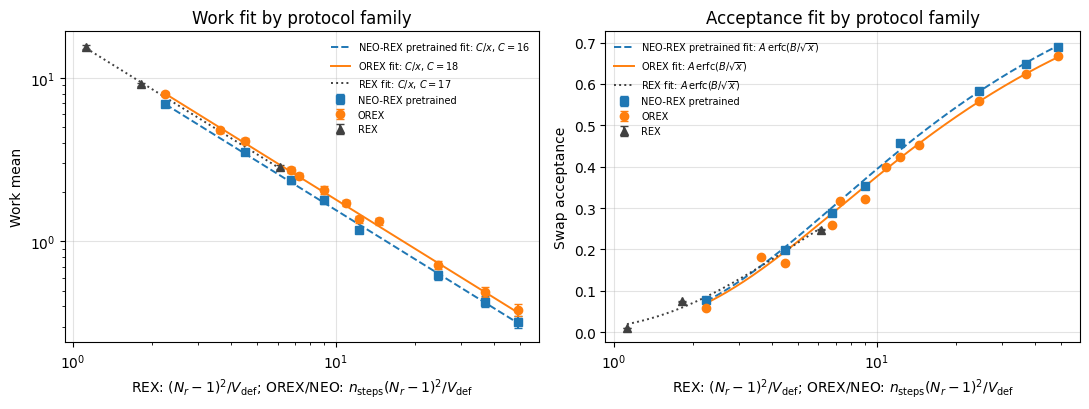

(PosixPath('two_plot_split_algorithm_fit_parameters.csv'),
       protocol_family  n_points     C_work  C_work_sem  work_rmse  \
 0  NEO-REX pretrained         8  15.539743    0.267830   0.056819   
 1                OREX        12  18.009560    0.216997   0.081803   
 2                 REX         3  17.117525    0.243919   0.216073   
 
    A_acceptance  B_acceptance  A_acceptance_sem  B_acceptance_sem  \
 0      0.984710      1.882407          0.002343          0.005817   
 1      0.948282      1.896480          0.002076          0.004350   
 2      0.740223      1.669087          0.007709          0.008001   
 
    acceptance_rmse  
 0         0.009756  
 1         0.017614  
 2         0.010726  )

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))
markers = {'REX': '^', 'OREX': 'o', 'NEO-REX pretrained': 's'}
colors = {'REX': '0.25', 'OREX': 'tab:orange', 'NEO-REX pretrained': 'tab:blue'}
line_styles = {'REX': ':', 'OREX': '-', 'NEO-REX pretrained': '--'}

for family, sub in fit_data.groupby('protocol_family', sort=True):
    color = colors.get(family, '0.3')
    marker = markers.get(family, 'o')
    axes[0].errorbar(
        sub['x_split'], sub['work_mean'], yerr=sub['work_sem_fit'],
        marker=marker, linestyle='None', color=color, capsize=3,
        label=family,
    )
    axes[1].errorbar(
        sub['x_split'], sub['swap_acceptance'], yerr=sub['swap_acceptance_sem_fit'],
        marker=marker, linestyle='None', color=color, capsize=3,
        label=family,
    )

for _, row in fit_summary.iterrows():
    family = row['protocol_family']
    sub = fit_data[fit_data['protocol_family'].eq(family)]
    xs = np.geomspace(sub['x_split'].min(), sub['x_split'].max(), 300)
    color = colors.get(family, '0.3')
    ls = line_styles.get(family, '-')
    axes[0].plot(
        xs, work_model(xs, row['C_work']), color=color, linestyle=ls, linewidth=1.4,
        label=fr'{family} fit: $C/x$, $C={row["C_work"]:.2g}$',
    )
    axes[1].plot(
        xs, acceptance_model(xs, row['A_acceptance'], row['B_acceptance']), color=color, linestyle=ls, linewidth=1.4,
        label=fr'{family} fit: $A\,\mathrm{{erfc}}(B/\sqrt{{x}})$',
    )

axes[0].set_title('Work fit by protocol family')
axes[0].set_xlabel(x_label_split)
axes[0].set_ylabel('Work mean')
axes[0].set_xscale('log')
axes[0].set_yscale('log')

axes[1].set_title('Acceptance fit by protocol family')
axes[1].set_xlabel(x_label_split)
axes[1].set_ylabel('Swap acceptance')
axes[1].set_xscale('log')

for ax in axes:
    ax.grid(True, alpha=0.35)
    ax.legend(frameon=False, fontsize=7, loc='best')

fig.tight_layout()
fig.savefig(FIG_DIR / 'two_plot_split_algorithm_fits.png', dpi=180, bbox_inches='tight')
fig.savefig(FIG_DIR / 'two_plot_split_algorithm_fits.pdf', bbox_inches='tight')
plt.show()

fit_csv = OUT_DIR / 'two_plot_split_algorithm_fit_parameters.csv'
fit_summary.to_csv(fit_csv, index=False)
fit_csv, fit_summary
